In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
cars_data=pd.read_csv('Car_Details_Project.csv')

In [4]:
cars_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,torque
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,5.0,205.0 Nm @ 1750 rpm
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,5.0,248.3 Nm @ 2000 rpm
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,5.0,238.4 Nm @ 2250 rpm
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,NaN,246.3 Nm @ 2500 rpm
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,5.0,212.6 Nm @ 1750 rpm


In [5]:
cars_data.shape

(8128, 13)

In [6]:
cars_data.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,torque
8123,Honda City 2017-2020 EXi,2014,1168000,26867,Diesel,Dealer,Manual,Fourth & Above Owner,26.32 kmpl,1199 CC,75.61 bhp,5.0,194.4 Nm @ 1500 rpm
8124,Maruti Swift VXI BSIII,2016,1725000,44343,Diesel,Individual,Manual,First Owner,23.77 kmpl,1497 CC,122.9 bhp,7.0,260.3 Nm @ 2500 rpm
8125,Maruti Swift Dzire VDi,2020,1712000,117281,Diesel,Individual,Automatic,First Owner,26.15 kmpl,1591 CC,111.09 bhp,5.0,276.9 Nm @ 2000 rpm
8126,Skoda Rapid 1.5 TDI Ambition,2008,1415000,98920,Petrol,Individual,Manual,First Owner,19.73 kmpl,2494 CC,173.29 bhp,5.0,427.3 Nm @ 2000 rpm
8127,Hyundai Verna VTVT 1.6 SX,2003,608000,31628,Petrol,Individual,Manual,First Owner,23.01 kmpl,1199 CC,56.27 bhp,7.0,168.7 Nm @ 1750 rpm


In [7]:
# torque - torque tells us how strongly an engine can rotate the wheels. it will not make much scence so we will drop this.(unneccessary col.)

In [8]:
cars_data.drop(columns=['torque'],inplace = True)
cars_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,NaN
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,5.0


In [9]:
cars_data.shape

(8128, 12)

### PREPROCESSING

#### NULL CHECKS

In [10]:
cars_data.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          162
engine           121
max_power        162
seats             81
dtype: int64

In [11]:
#we will not drop the missing-value rows because that would reduce dataset and cause loss of useful information
#.so we are filling the missing numerical values with the median because median is less affected by outliers,
# which are common in car-related numerical features.

In [12]:
#We decided to fill these missing values rather than delete the rows.
#But there is one important thing: mileage, engine, and max_power contain values like:
#23.4 kmpl
#1248 CC
#74 bhp
#So first we need to remove the units and convert them into numbers.

In [13]:
def get_mileage(mileage):
    return float(str(mileage).split(' ')[0])

cars_data['mileage'] = cars_data['mileage'].apply(get_mileage)

In [14]:
cars_data['mileage'].head()

0    23.40
1    21.14
2    17.70
3    23.00
4    16.10
Name: mileage, dtype: float64

In [15]:
def get_engine(engine):
    return float(str(engine).split(' ')[0])

cars_data['engine'] = cars_data['engine'].apply(get_engine)

In [16]:
cars_data['engine'].head()

0    1248.0
1    1498.0
2    1497.0
3    1396.0
4    1298.0
Name: engine, dtype: float64

In [17]:
def get_max_power(max_power):
    return float(str(max_power).split(' ')[0])

cars_data['max_power'] = cars_data['max_power'].apply(get_max_power)

In [18]:
cars_data['max_power'].head()

0     74.00
1    103.52
2     78.00
3     90.00
4     88.20
Name: max_power, dtype: float64

In [19]:
# Now fill the missing values

In [20]:
cars_data['mileage'] = cars_data['mileage'].fillna(cars_data['mileage'].median())

cars_data['engine'] = cars_data['engine'].fillna(cars_data['engine'].median())

cars_data['max_power'] = cars_data['max_power'].fillna(cars_data['max_power'].median())

cars_data['seats'] = cars_data['seats'].fillna(cars_data['seats'].median())

In [21]:
cars_data.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64

In [22]:
#Don't fill the missing values before converting these three columns to numbers.
#Otherwise, you may have trouble calculating the median because the columns contain text such as "1248 CC".

#### DATA ANALYSIS / EDA

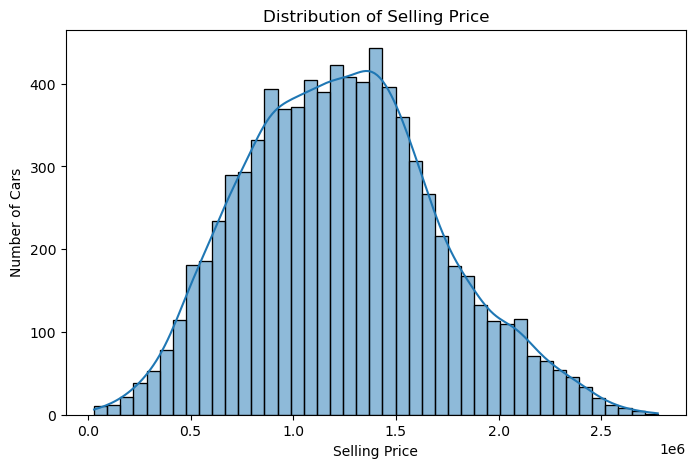

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(cars_data['selling_price'], kde=True)
plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.show()

In [24]:
### Visualization 2 — Distribution of numerical features

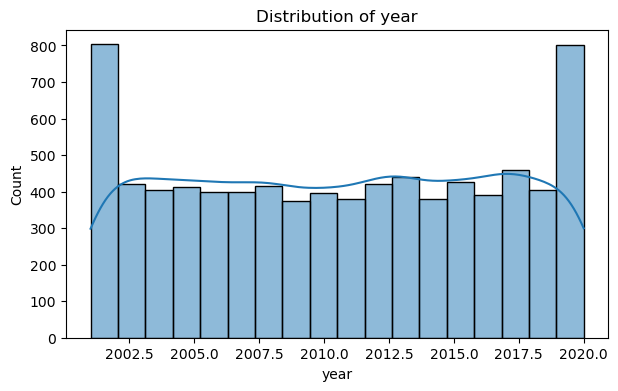

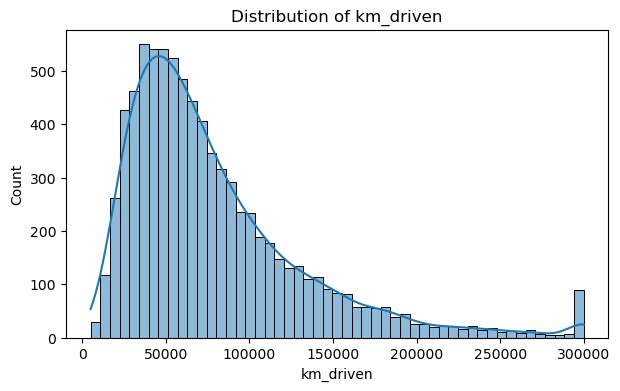

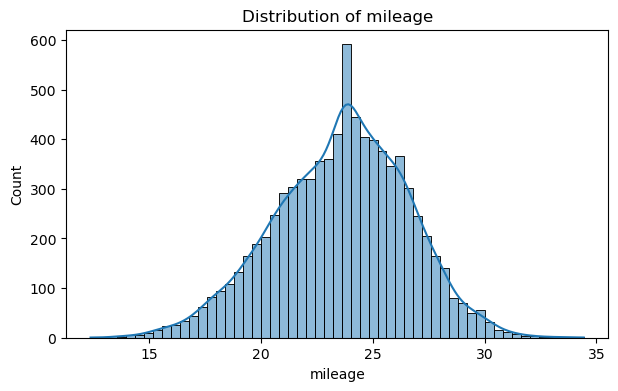

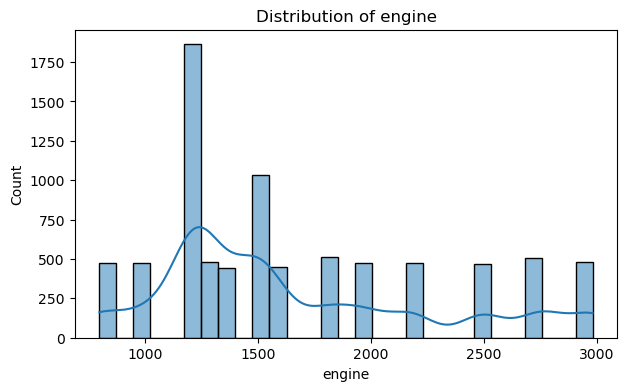

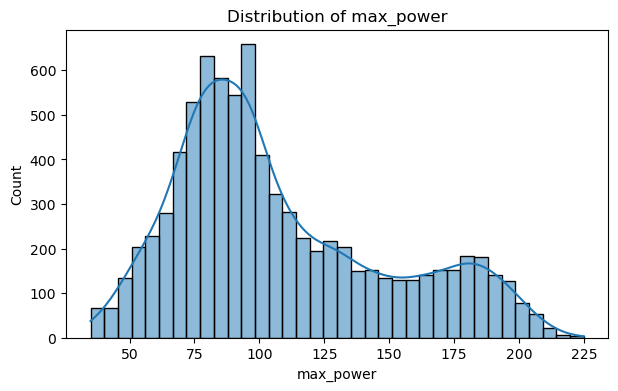

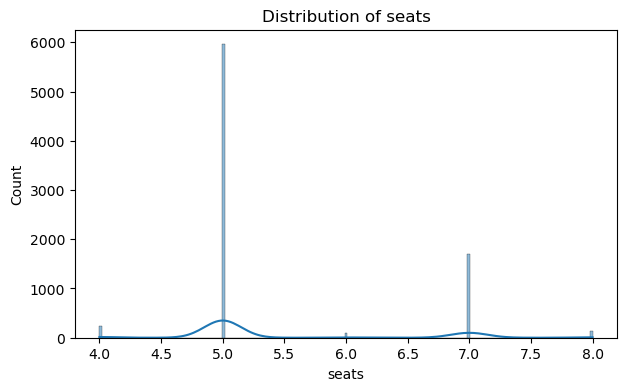

In [25]:
numeric_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(cars_data[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

In [26]:
### Visualization 3 — Categorical variables

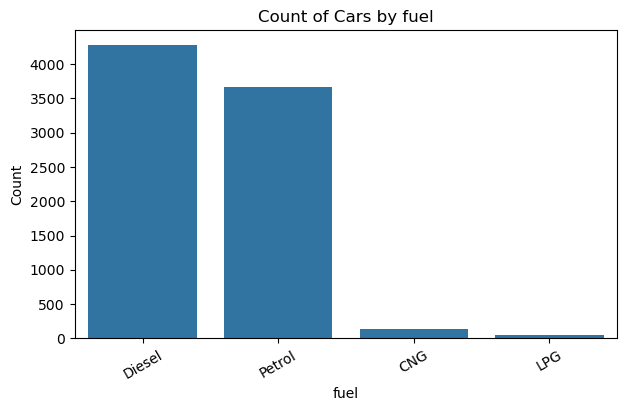

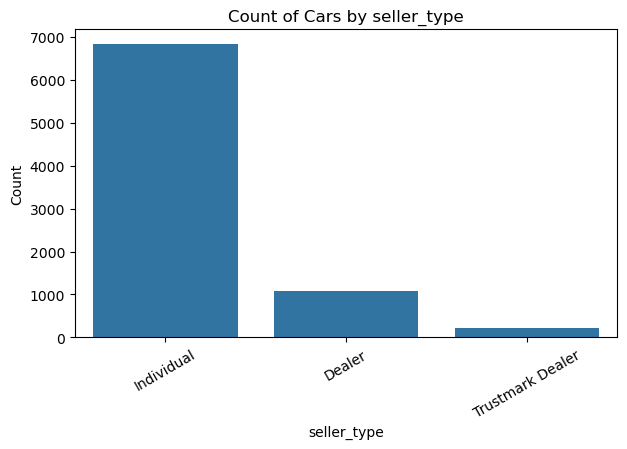

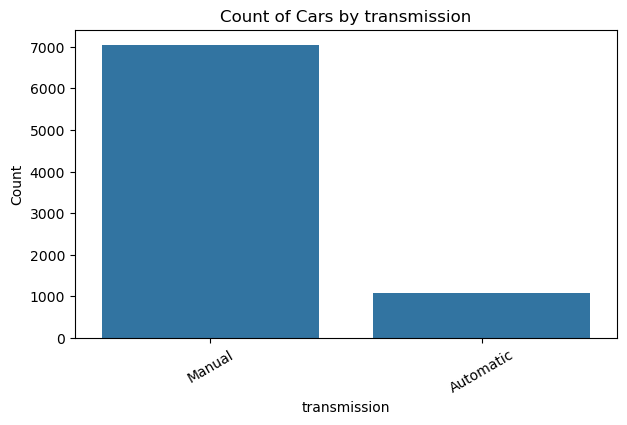

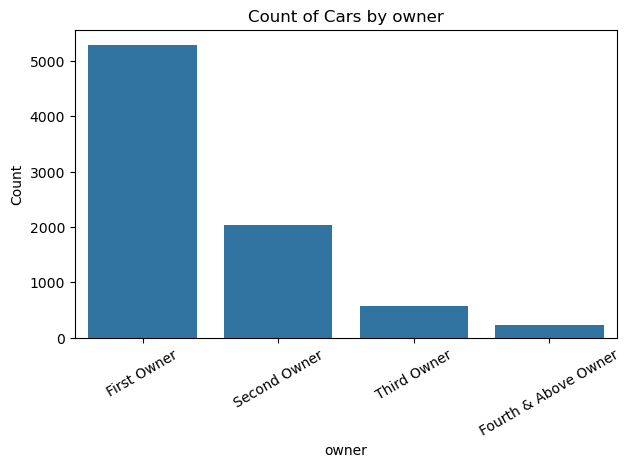

In [27]:
categorical_cols = ['fuel', 'seller_type', 'transmission', 'owner']

for col in categorical_cols:
    plt.figure(figsize=(7,4))
    sns.countplot(data=cars_data, x=col)
    plt.title(f'Count of Cars by {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=30)
    plt.show()

In [28]:
### Visualization 4 — Year vs Selling Price

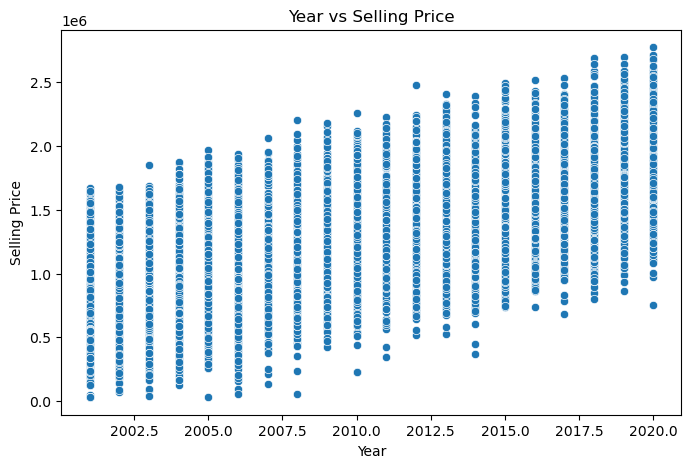

In [29]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=cars_data, x='year', y='selling_price')
plt.title('Year vs Selling Price')
plt.xlabel('Year')
plt.ylabel('Selling Price')
plt.show()

In [30]:
### Visualization 5 — Km Driven vs Selling Price

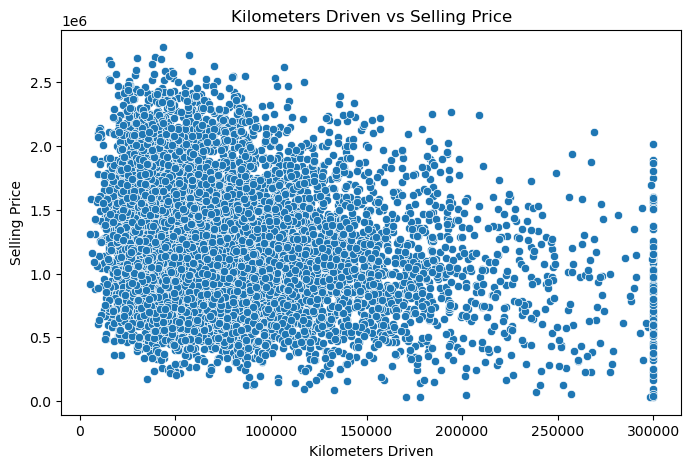

In [31]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=cars_data, x='km_driven', y='selling_price')
plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price')
plt.show()

In [32]:
### Visualization 6 — Engine vs Selling Price

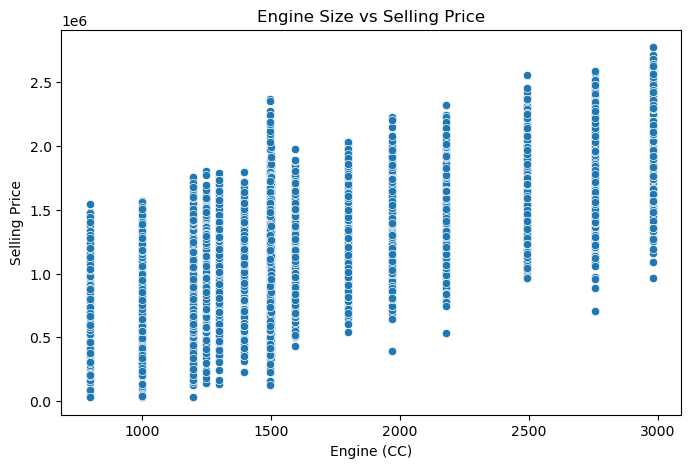

In [33]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=cars_data, x='engine', y='selling_price')
plt.title('Engine Size vs Selling Price')
plt.xlabel('Engine (CC)')
plt.ylabel('Selling Price')
plt.show()

In [34]:
### Visualization 7 — Max Power vs Selling Price

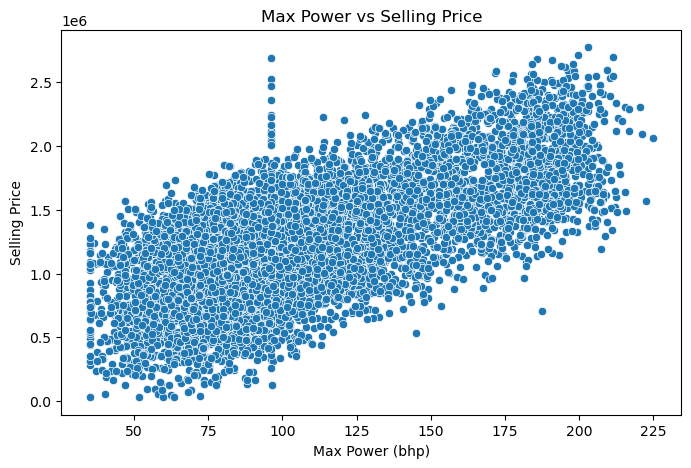

In [35]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=cars_data, x='max_power', y='selling_price')
plt.title('Max Power vs Selling Price')
plt.xlabel('Max Power (bhp)')
plt.ylabel('Selling Price')
plt.show()

In [36]:
### Visualization 8 — Fuel vs Selling Price

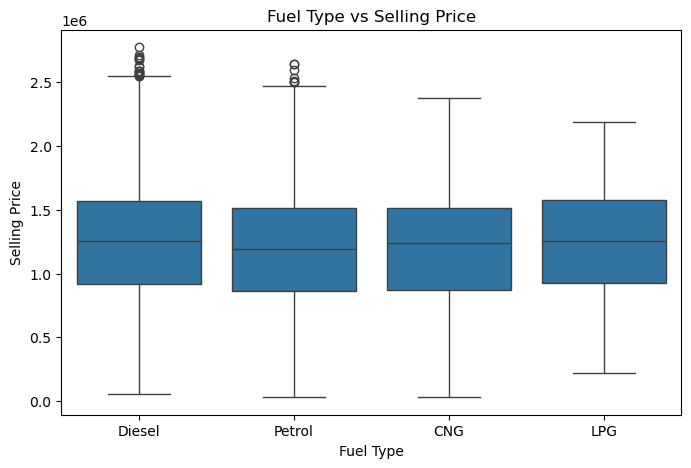

In [37]:
plt.figure(figsize=(8,5))
sns.boxplot(data=cars_data, x='fuel', y='selling_price')
plt.title('Fuel Type vs Selling Price')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')
plt.show()

In [38]:
### Visualization 9 — Outlier Detection

In [39]:
#### #### OUTLIER ANALYSIS

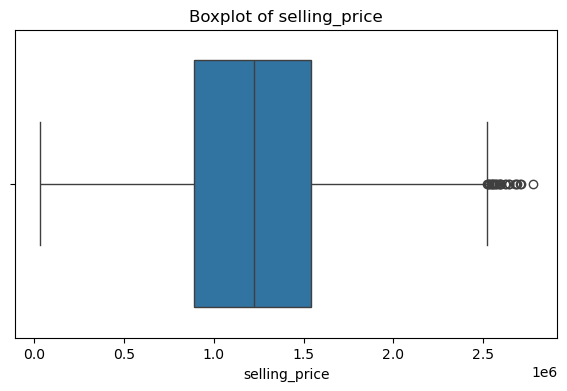

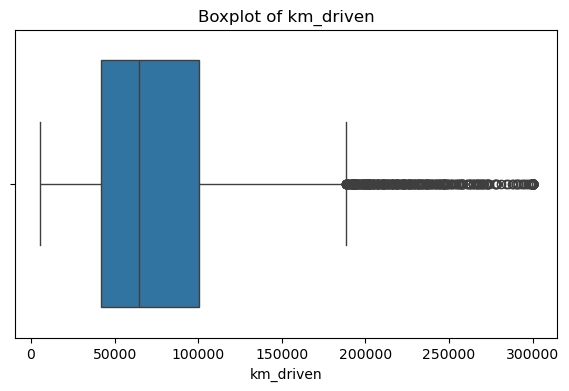

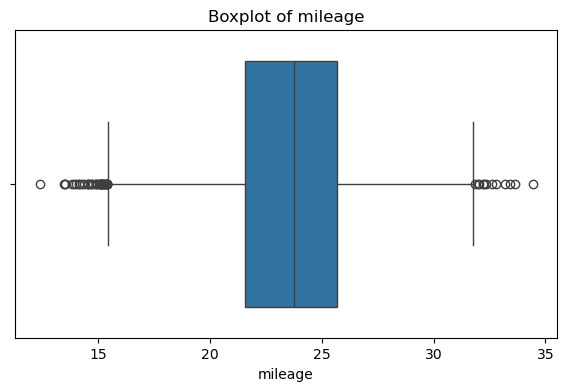

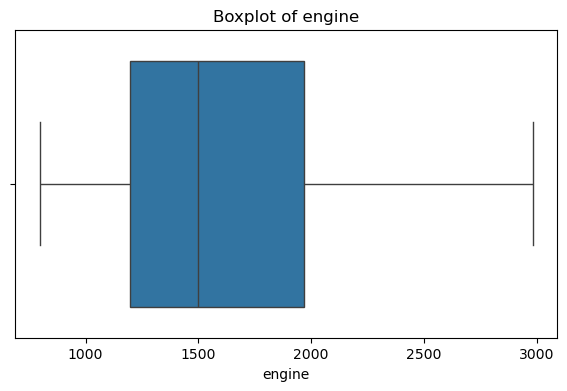

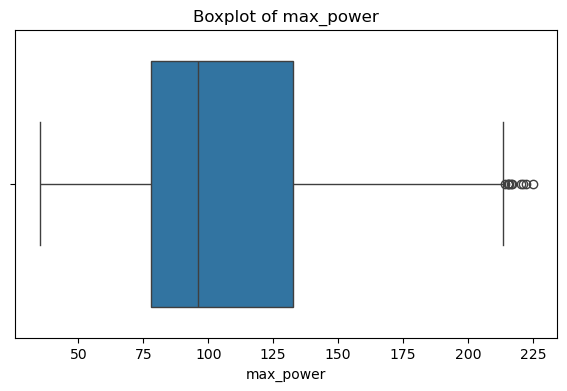

In [40]:
numeric_cols = ['selling_price', 'km_driven', 'mileage', 'engine', 'max_power']

for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=cars_data[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

In [41]:
### Visualization 10 — Correlation Heatmap

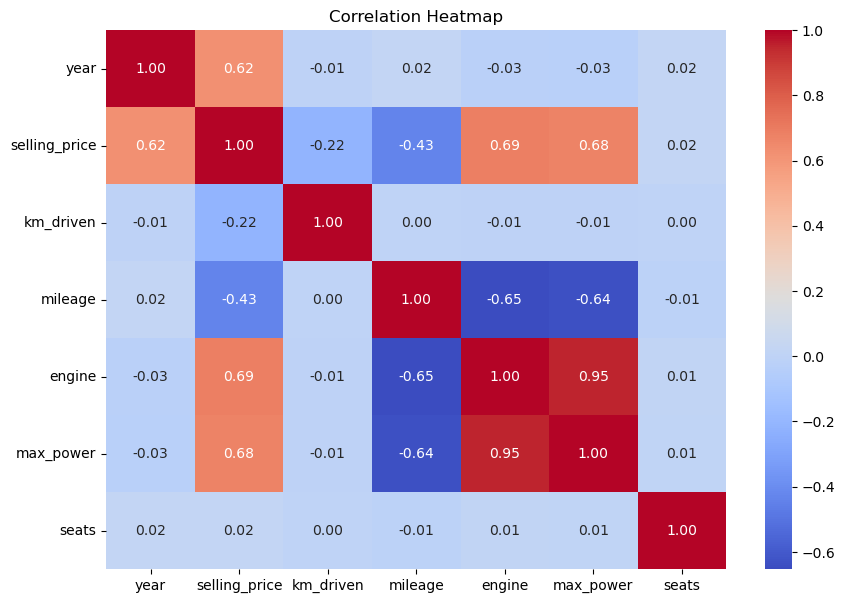

In [43]:
plt.figure(figsize=(10,7))

sns.heatmap(
    cars_data.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [44]:
for col in cars_data.columns:
    print("Unique values of " + col)
    print(cars_data[col].unique())
    print("***********************************************\n")

Unique values of name
['Maruti Swift Dzire VDI' 'Skoda Rapid 1.5 TDI Ambition'
 'Honda City 2017-2020 EXi' 'Hyundai i20 Sportz Diesel'
 'Maruti Swift VXI BSIII' 'Renault Duster 110PS Diesel RxL'
 'Ford EcoSport 1.5 Diesel Titanium Plus BSIV' 'Honda WR-V i-DTEC VX'
 'Ford Figo Diesel Celebration Edition' 'Hyundai Xcent 1.2 VTVT E Plus'
 'Maruti Celerio VXI' 'Maruti Ertiga SHVS VDI' 'Maruti Swift Dzire VDi'
 'Maruti Zen LX' 'Maruti Wagon R LXI Minor' 'Maruti Baleno Delta 1.2'
 'Mahindra KUV 100 mFALCON G80 K8 5str' 'Hyundai Verna VTVT 1.6 SX'
 'Toyota Fortuner 4x4 MT' 'Hyundai Creta 1.6 CRDi SX'
 'Hyundai i20 1.4 CRDi Asta' 'Maruti Wagon R LXI DUO BSIII'
 'Toyota Etios VXD' 'Maruti 800 DX BSII' 'Maruti Alto LX']
***********************************************

Unique values of year
[2014 2006 2010 2007 2019 2011 2004 2008 2003 2002 2012 2001 2017 2016
 2015 2020 2005 2009 2018 2013]
***********************************************

Unique values of selling_price
[ 450000  370000  158000 .

In [45]:
# here we are seperating the brand name from car name like --Maruti Swift VXI BSIII
def get_brand_name(car_name):
     return car_name.split(' ')[0]

In [46]:
get_brand_name('Maruti Swift VXI BSIII')

'Maruti'

In [47]:
cars_data['name'] = cars_data['name'].apply(get_brand_name)

In [48]:
cars_data['name'].unique()

array(['Maruti', 'Skoda', 'Honda', 'Hyundai', 'Renault', 'Ford',
       'Mahindra', 'Toyota'], dtype=object)

In [49]:
#Don't run the apply() line repeatedly after the column
#has already been converted to brands.

In [50]:
for col in cars_data.columns:
    print("Unique values of " + col)
    print(cars_data[col].unique())
    print("***********************************************\n")

Unique values of name
['Maruti' 'Skoda' 'Honda' 'Hyundai' 'Renault' 'Ford' 'Mahindra' 'Toyota']
***********************************************

Unique values of year
[2014 2006 2010 2007 2019 2011 2004 2008 2003 2002 2012 2001 2017 2016
 2015 2020 2005 2009 2018 2013]
***********************************************

Unique values of selling_price
[ 450000  370000  158000 ... 2075000 2566000 1739000]
***********************************************

Unique values of km_driven
[145500 120000 140000 ... 117281  98920  31628]
***********************************************

Unique values of fuel
['Diesel' 'Petrol' 'CNG' 'LPG']
***********************************************

Unique values of seller_type
['Individual' 'Dealer' 'Trustmark Dealer']
***********************************************

Unique values of transmission
['Manual' 'Automatic']
***********************************************

Unique values of owner
['First Owner' 'Second Owner' 'Third Owner' 'Fourth & Above Owner']
******

In [51]:
# The name column contains categorical data, so I converted the car brands into numerical values
#cars_data['name'].replace(['Maruti', 'Skoda', 'Honda', 'Ford', 'Renault', 'Hyundai',
 #      'Mahindra', 'Toyota'],[1,2,3,4,5,6,7,8],inplace = True)

In [52]:
cars_data['name'].replace(
    ['Maruti', 'Skoda', 'Honda', 'Ford', 'Renault', 'Hyundai',
     'Mahindra', 'Toyota'],
    [1, 2, 3, 4, 5, 6, 7, 8],
inplace=True)

In [53]:
cars_data['name'].unique()

array([1, 2, 3, 6, 5, 4, 7, 8])

In [54]:
cars_data['transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

In [55]:
cars_data['transmission'].replace(['Manual', 'Automatic'],[1,2],inplace=True)

In [56]:
cars_data['transmission'].unique()

array([1, 2])

In [57]:
cars_data['seller_type'].unique()

array(['Individual', 'Dealer', 'Trustmark Dealer'], dtype=object)

In [58]:
cars_data['seller_type'].replace(['Individual', 'Dealer', 'Trustmark Dealer'],[1,2,3],inplace=True)

In [59]:
cars_data['seller_type'].unique()

array([1, 2, 3])

In [60]:
cars_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   int64  
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   int64  
 6   transmission   8128 non-null   int64  
 7   owner          8128 non-null   object 
 8   mileage        8128 non-null   float64
 9   engine         8128 non-null   float64
 10  max_power      8128 non-null   float64
 11  seats          8128 non-null   float64
dtypes: float64(4), int64(6), object(2)
memory usage: 762.1+ KB


In [61]:
cars_data['fuel'].unique()

array(['Diesel', 'Petrol', 'CNG', 'LPG'], dtype=object)

In [62]:
cars_data['fuel'].replace(['Diesel', 'Petrol', 'CNG', 'LPG'],[1,2,3,4],inplace=True)

In [63]:
cars_data['fuel'].unique()

array([1, 2, 3, 4])

In [64]:
cars_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   int64  
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   int64  
 5   seller_type    8128 non-null   int64  
 6   transmission   8128 non-null   int64  
 7   owner          8128 non-null   object 
 8   mileage        8128 non-null   float64
 9   engine         8128 non-null   float64
 10  max_power      8128 non-null   float64
 11  seats          8128 non-null   float64
dtypes: float64(4), int64(7), object(1)
memory usage: 762.1+ KB


In [65]:
cars_data['owner'].unique()

array(['First Owner', 'Second Owner', 'Third Owner',
       'Fourth & Above Owner'], dtype=object)

In [66]:
cars_data['owner'].replace(['First Owner', 'Second Owner', 'Third Owner',
       'Fourth & Above Owner'],[1,2,3,4],inplace=True)

In [67]:
cars_data['owner'].unique()

array([1, 2, 3, 4])

In [68]:
cars_data

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,1,2014,450000,145500,1,1,1,1,23.40,1248.0,74.00,5.0
1,2,2014,370000,120000,1,1,1,2,21.14,1498.0,103.52,5.0
2,3,2006,158000,140000,2,1,1,3,17.70,1497.0,78.00,5.0
3,6,2010,225000,127000,1,1,1,1,23.00,1396.0,90.00,5.0
4,1,2007,130000,120000,2,1,1,1,16.10,1298.0,88.20,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
8123,3,2014,1168000,26867,1,2,1,4,26.32,1199.0,75.61,5.0
8124,1,2016,1725000,44343,1,1,1,1,23.77,1497.0,122.90,7.0
8125,1,2020,1712000,117281,1,1,2,1,26.15,1591.0,111.09,5.0
8126,2,2008,1415000,98920,2,1,1,1,19.73,2494.0,173.29,5.0


In [69]:
### Now we should check which numerical features have a strong relationship with selling_price.

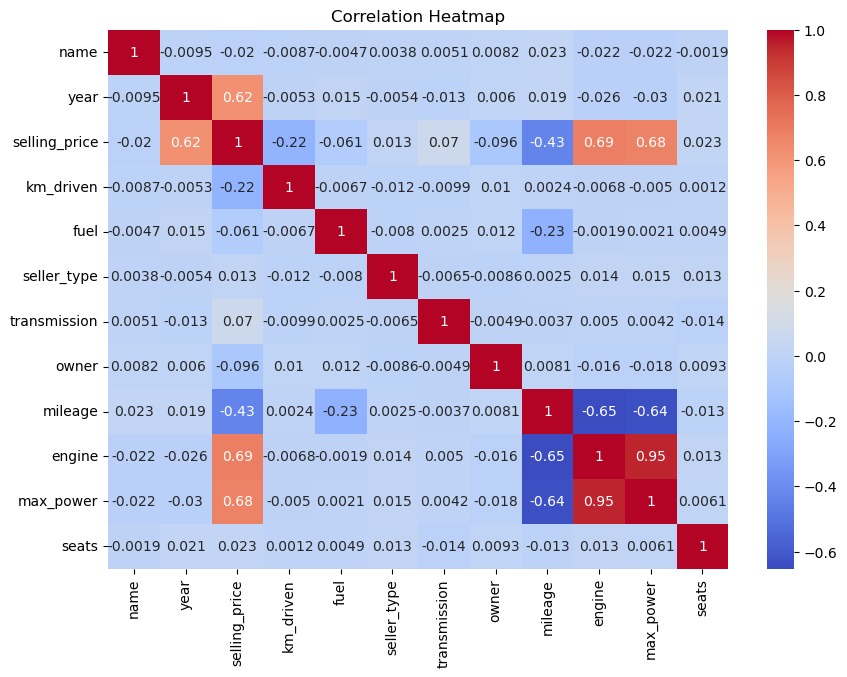

In [70]:
plt.figure(figsize=(10, 7))

sns.heatmap(cars_data.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [71]:
### Outlier Detection Visualization

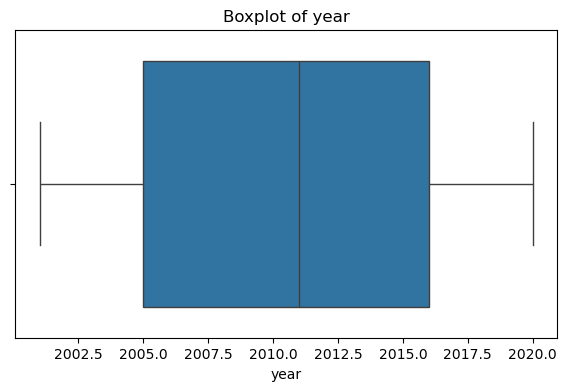

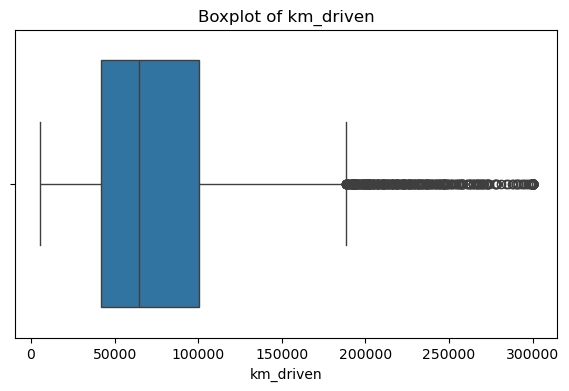

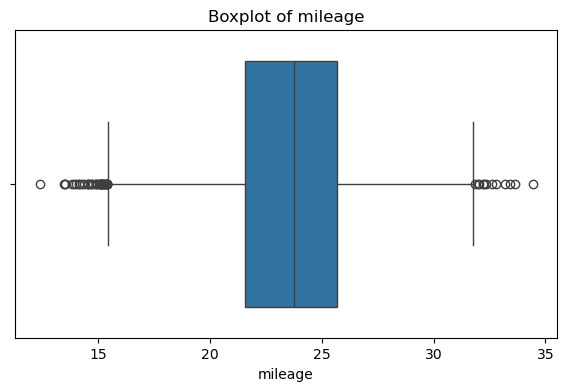

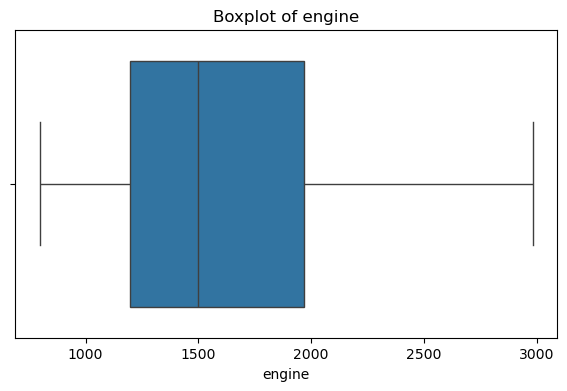

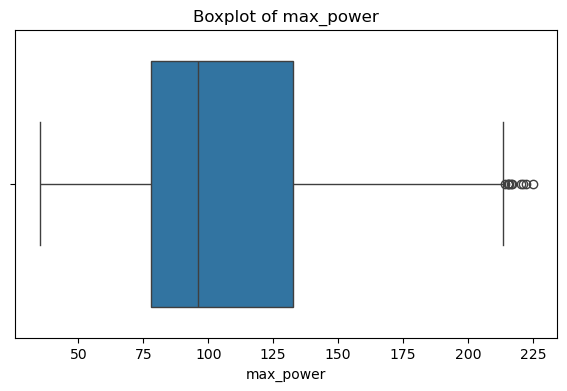

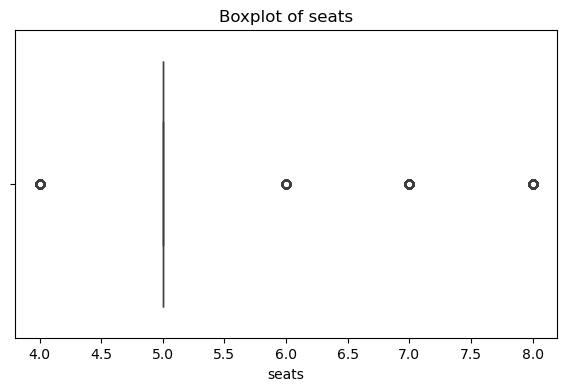

In [72]:
numerical_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    
    sns.boxplot(x=cars_data[col])
    
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    
    plt.show()

In [73]:
input_data=cars_data.drop(columns=['selling_price'])
output_data=cars_data['selling_price']

In [74]:
input_data

,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,1,2014,145500,1,1,1,1,23.40,1248.0,74.00,5.0
1,2,2014,120000,1,1,1,2,21.14,1498.0,103.52,5.0
2,3,2006,140000,2,1,1,3,17.70,1497.0,78.00,5.0
3,6,2010,127000,1,1,1,1,23.00,1396.0,90.00,5.0
4,1,2007,120000,2,1,1,1,16.10,1298.0,88.20,5.0
...,...,...,...,...,...,...,...,...,...,...,...
8123,3,2014,26867,1,2,1,4,26.32,1199.0,75.61,5.0
8124,1,2016,44343,1,1,1,1,23.77,1497.0,122.90,7.0
8125,1,2020,117281,1,1,2,1,26.15,1591.0,111.09,5.0
8126,2,2008,98920,2,1,1,1,19.73,2494.0,173.29,5.0


In [75]:
output_data

0        450000
1        370000
2        158000
3        225000
4        130000
         ...   
8123    1168000
8124    1725000
8125    1712000
8126    1415000
8127     608000
Name: selling_price, Length: 8128, dtype: int64

In [76]:
x_train,x_test,y_train,y_test = train_test_split(input_data,output_data,test_size=0.2,random_state=42)

### MODEL CREATION

In [77]:
model = LinearRegression()

#### train the model

In [78]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [79]:
### Linear Regression Coefficient Analysis

In [80]:
coefficients = pd.DataFrame({
    "Feature": x_train.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
5,transmission,102406.157406
1,year,52282.711110
9,max_power,3346.523515
4,seller_type,2764.587849
10,seats,2233.149657
8,engine,328.263023
7,mileage,219.102385
0,name,133.175017
2,km_driven,-1.853552
6,owner,-52766.194483


In [81]:
predict = model.predict(x_test)

In [82]:
### MODEL EVALUATION

In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predict)
mse = mean_squared_error(y_test, predict)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predict)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 83927.42044895525
Mean Squared Error (MSE): 11149953730.722052
Root Mean Squared Error (RMSE): 105593.34131810609
R² Score: 0.9481838970567192


In [84]:
### Actual vs Predicted Price graph

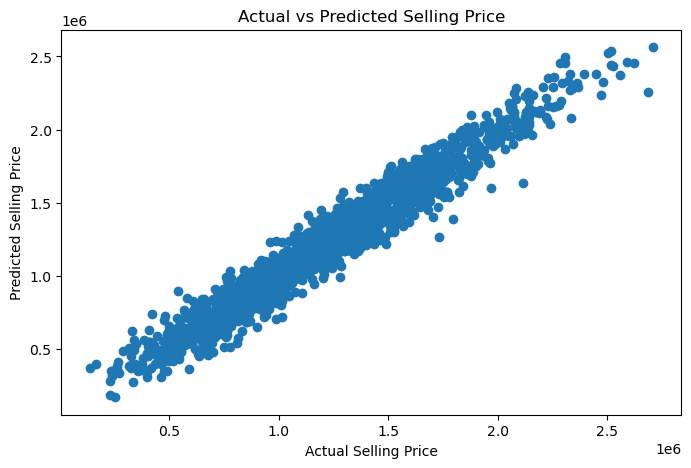

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predict)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")

plt.show()

In [86]:
### Residual/Error Distribution Plot

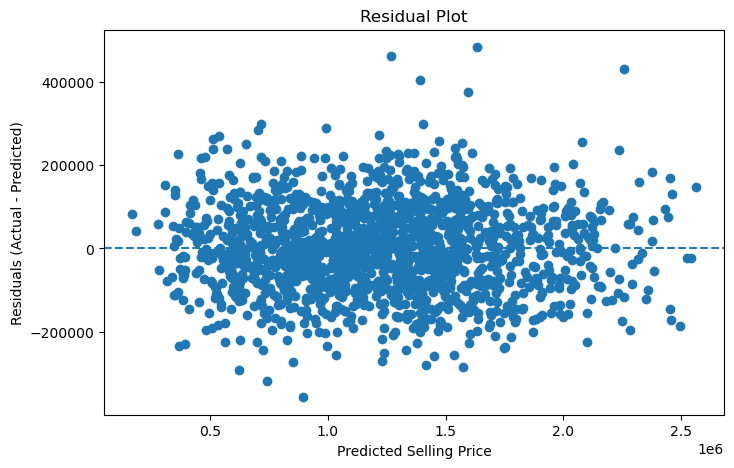

In [87]:
# Calculate residuals
residuals = y_test - predict

plt.figure(figsize=(8, 5))

plt.scatter(predict, residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")

plt.show()

In [88]:
###distribution plot of the residuals

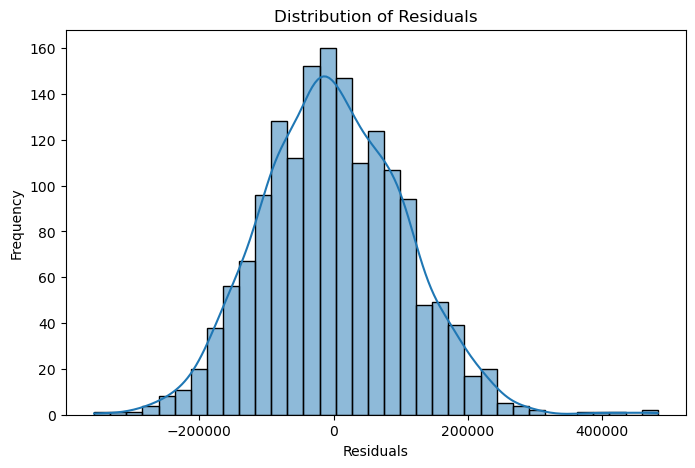

In [89]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

In [90]:
### Q-Q Plot for Residuals

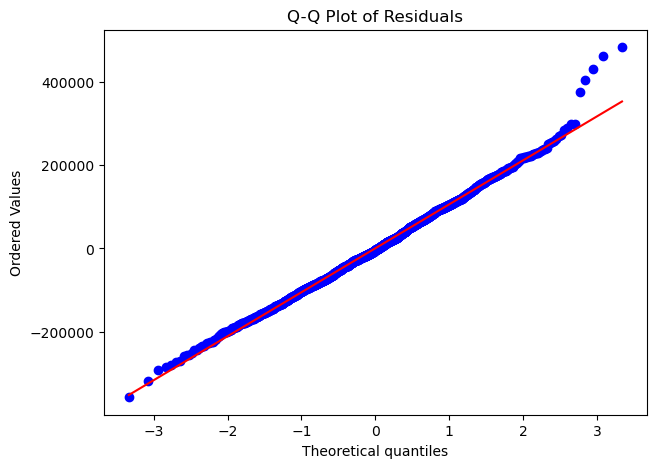

In [91]:
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Residuals")
plt.show()

In [92]:
### Actual vs Predicted Price Comparison Table

In [93]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predict
})

comparison["Difference"] = comparison["Actual Price"] - comparison["Predicted Price"]

comparison.head(10)

,Actual Price,Predicted Price,Difference
0,579000,8.502586e+05,-271258.551061
1,1368000,1.189884e+06,178115.952020
2,1548000,1.626202e+06,-78201.617520
3,1861000,1.695069e+06,165930.949776
4,419000,5.367662e+05,-117766.161399
5,1310000,1.384837e+06,-74837.276757
6,1130000,1.033560e+06,96439.538267
7,1200000,1.149932e+06,50068.092039
8,1236000,1.390643e+06,-154642.709947
9,1301000,1.390403e+06,-89402.790942


In [94]:
### Regression Line / Relationship Check

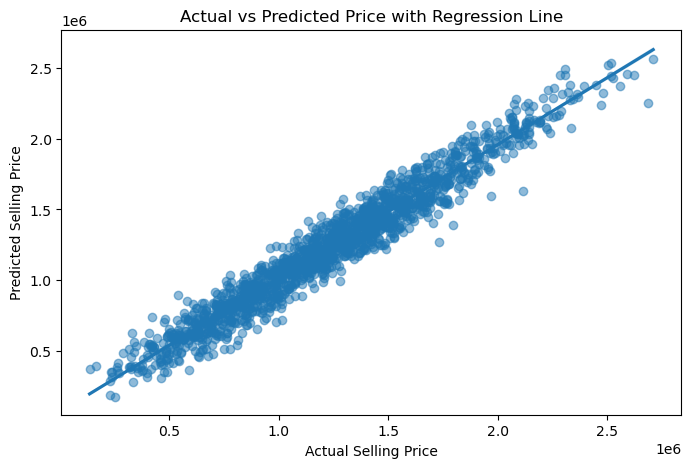

In [95]:
plt.figure(figsize=(8, 5))

sns.regplot(x=y_test, y=predict, scatter_kws={"alpha": 0.5})

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Price with Regression Line")

plt.show()

In [96]:
predict

array([ 850258.55106074, 1189884.04798   , 1626201.6175205 , ...,
       1451866.03296894, 1731987.37704977,  604081.47406156],
      shape=(1626,))

In [97]:
x_train

,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
6518,1,2011,90761,1,1,1,1,26.94,1396.0,95.68,5.0
6144,8,2020,81570,1,2,1,1,27.64,1198.0,86.52,5.0
6381,8,2010,55325,1,1,1,1,24.52,1298.0,87.75,5.0
438,1,2002,198289,1,1,1,2,22.42,2755.0,185.89,7.0
5939,8,2013,116641,2,2,1,2,22.22,1798.0,102.76,7.0
...,...,...,...,...,...,...,...,...,...,...,...
5226,1,2003,32409,2,1,1,1,23.65,1298.0,75.47,5.0
5390,1,2017,57581,2,1,1,2,19.31,2755.0,173.12,5.0
860,5,2011,65083,1,2,1,2,23.17,1798.0,118.59,7.0
7603,1,2019,122529,1,1,1,1,21.65,1591.0,107.67,7.0


In [98]:
x_test

,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
1971,3,2004,39275,2,1,1,2,21.05,1497.0,107.98,7.0
4664,1,2005,42901,1,1,1,1,20.19,1497.0,163.94,5.0
5448,1,2013,79538,2,1,2,1,21.88,1968.0,130.33,5.0
3333,1,2015,135387,1,2,1,1,22.02,2179.0,142.05,5.0
2316,1,2005,106070,2,1,1,3,21.43,1197.0,82.26,5.0
...,...,...,...,...,...,...,...,...,...,...,...
1149,2,2013,68651,1,1,1,1,18.54,2179.0,135.82,5.0
5002,1,2020,75658,1,1,1,1,26.00,1197.0,75.08,5.0
6008,1,2017,51905,2,1,1,3,27.29,1591.0,99.20,5.0
2283,3,2007,97345,1,1,1,1,20.11,2982.0,179.10,5.0


In [99]:
y_train

6518    1148000
6144    1553000
6381    1038000
438     1136000
5939    1277000
         ...   
5226     727000
5390    2193000
860     1376000
7603    1727000
7270    1066000
Name: selling_price, Length: 6502, dtype: int64

In [100]:
y_test

1971     579000
4664    1368000
5448    1548000
3333    1861000
2316     419000
         ...   
1149    1673000
5002    1560000
6008    1363000
2283    1702000
5428     491000
Name: selling_price, Length: 1626, dtype: int64

In [101]:
x_train.head(1)

,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
6518,1,2011,90761,1,1,1,1,26.94,1396.0,95.68,5.0


In [102]:
#input_data_model= pd.DataFrame([[4,2009,46136,4,1,1,1,23.97,1298.0,65.28,5.0]],
                            #columns=['name','year','km_driven','fuel','seller_type','transmission','owner','mileage','engine','max_power','seats'])

In [103]:
#model.predict(input_data_model) #this is precdiction of 7811 th record. output will --->array([820015.08194219])

In [104]:
# now change the values
input_data_model= pd.DataFrame([[4,2010,46136,4,1,1,1,23.97,1298.0,65.28,5.0]],
                               columns=['name','year','km_driven','fuel','seller_type','transmission','owner','mileage','engine','max_power','seats'])

In [107]:
model.predict(input_data_model)

array([874195.16236217])

In [108]:
import pickle as pk

In [109]:
import pickle as pk
import os

# Save the trained Linear Regression model
with open("model.pkl", "wb") as file:
    pk.dump(model, file)

# Check whether the model file was saved
if os.path.exists("model.pkl"):
    print("Model saved successfully as model.pkl")
else:
    print("Model was not saved")

Model saved successfully as model.pkl
